# Yugaantar DevForge Hackathon — Track 2: "Multiverse of Monsoon"
## 2D Residual U-Net Climate Forecasting & Autoregressive Rollout Engine

This notebook implements an end-to-end, high-performance training and verification pipeline:
- **Spatial Grid:** 32 × 36 daily Indian climate records (2005–2021).
- **6 Dynamic Channels:** `t2m` (K), `tp` (mm/day), `u10` (m/s), `v10` (m/s), `msl` (Pa), `tcwv` (kg/m²).
- **2 Static Channels:** `land_sea_mask`, `orography_m` (normalized).
- **2 Seasonal Channels:** Day-of-Year $\sin$ and $\cos$ dynamic encoding.
- **Model:** 2D Residual U-Net (~1.50M parameters) predicting normalized day-over-day deltas.
- **Two-Stage Training:**
  - Stage 1: 1-step warm-up (Epochs 1–30) with Huber loss (2.0× weight on `tp`).
  - Stage 2: 4-step autoregressive rollout fine-tuning (Epochs 31–60).
- **Verification:** Persistence benchmark, physical stability, shock causality maps, and ONNX CPU export.


### 1. Environment Setup & Kaggle Dependencies
Install required packages (`xarray`, `netCDF4`, `onnx`, `onnxruntime`) and verify GPU availability.


In [1]:
!pip install -q xarray netCDF4 onnx onnxruntime matplotlib

import os
import sys
import glob
import math
import json
import time
import zipfile
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Kaggle GPU check
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Device: {device}")
if device.type == "cuda":
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Version: {torch.version.cuda}")


Active Device: cuda
GPU Model: Tesla T4
CUDA Version: 13.0


### 2. Auto-Detect Dataset & Setup Artifact Directory
Finds `india_climate_train.nc` anywhere inside `/kaggle/input/` and prepares `/kaggle/working/artifacts/`.


In [2]:
# Search for NetCDF file under /kaggle/input
def find_nc_file():
    patterns = [
        "/kaggle/input/**/india_climate_train.nc",
        "/kaggle/input/**/*.nc",
        "./india_climate_train.nc",
        "../india_climate_train.nc",
    ]
    for p in patterns:
        matches = glob.glob(p, recursive=True)
        for m in matches:
            if os.path.isfile(m):
                return os.path.abspath(m)
    return None

nc_path = find_nc_file()
if nc_path:
    print(f"Found NetCDF dataset at: {nc_path}")
else:
    print("Warning: NetCDF file not found under /kaggle/input. If testing locally, generating synthetic dataset...")
    # Synthetic generator for local / smoke testing
    times = pd.date_range("2005-01-01", "2021-12-31", freq="D")
    n_times = len(times)
    np.random.seed(42)
    t2m = 295.0 + 8.0 * np.sin(2 * np.pi * times.dayofyear.values[:, None, None] / 365.0) + np.random.randn(n_times, 32, 36) * 2.0
    tp = np.maximum(0.0, np.random.exponential(scale=4.0, size=(n_times, 32, 36)))
    u10 = np.random.randn(n_times, 32, 36) * 4.0 + 2.0
    v10 = np.random.randn(n_times, 32, 36) * 4.0 + 1.0
    msl = 101325.0 + np.random.randn(n_times, 32, 36) * 500.0
    tcwv = np.maximum(5.0, 35.0 + np.random.randn(n_times, 32, 36) * 10.0)
    lsm = (np.random.rand(32, 36) > 0.35).astype(np.float32)
    orog = np.abs(np.random.randn(32, 36) * 800.0).astype(np.float32)
    ds = xr.Dataset(
        data_vars={
            "t2m": (["time", "lat", "lon"], t2m.astype(np.float32)),
            "tp": (["time", "lat", "lon"], tp.astype(np.float32)),
            "u10": (["time", "lat", "lon"], u10.astype(np.float32)),
            "v10": (["time", "lat", "lon"], v10.astype(np.float32)),
            "msl": (["time", "lat", "lon"], msl.astype(np.float32)),
            "tcwv": (["time", "lat", "lon"], tcwv.astype(np.float32)),
            "land_sea_mask": (["lat", "lon"], lsm),
            "orography_m": (["lat", "lon"], orog),
        },
        coords={"time": times, "lat": np.linspace(8, 39, 32), "lon": np.linspace(68, 97, 36)}
    )
    nc_path = "india_climate_train.nc"
    ds.to_netcdf(nc_path)
    print(f"Generated synthetic dataset: {nc_path}")

artifact_dir = "/kaggle/working/artifacts"
if not os.path.exists("/kaggle/working"):
    artifact_dir = os.path.abspath("./artifacts")
os.makedirs(artifact_dir, exist_ok=True)
print(f"Artifact directory: {artifact_dir}")


Found NetCDF dataset at: /content/india_climate_train.nc
Artifact directory: /content/artifacts


### 3. Chronological Splits & Normalization (`stats.json`, `static_fields.npz`)
- **Train:** 2005–2018
- **Validation:** 2019
- **Holdout Test:** 2020–2021
- Mean and std computed **strictly** on the 2005–2018 Train split.
- `tp` (channel 1) has `log1p(np.maximum(tp, 0.0))` applied before computing its statistics.


In [4]:
DYNAMIC_CHANNELS = ["t2m", "tp", "u10", "v10", "msl", "tcwv"]
CHANNEL_UNITS = {"t2m": "K", "tp": "mm/day", "u10": "m/s", "v10": "m/s", "msl": "Pa", "tcwv": "kg/m^2"}

ds = xr.open_dataset(nc_path)
times = pd.to_datetime(ds.time.values)
years = times.year
doys = times.dayofyear.values

train_mask = (years >= 2005) & (years <= 2018)
val_mask = (years == 2019)
test_mask = (years >= 2020) & (years <= 2021)

print(f"Data splits: Train = {np.sum(train_mask)} days, Val = {np.sum(val_mask)} days, Test = {np.sum(test_mask)} days")

# Static fields
if "static" in ds:
    lsm = ds["static"].sel(static_channel="land_sea_mask").values.astype(np.float32)
    if "orography_m" in ds.static_channel.values:
        orog = ds["static"].sel(static_channel="orography_m").values.astype(np.float32)
    elif "orography" in ds.static_channel.values:
        orog = ds["static"].sel(static_channel="orography").values.astype(np.float32)
    else:
        orog = np.zeros((32, 36), dtype=np.float32)
else:
    lsm = ds["land_sea_mask"].values.astype(np.float32) if "land_sea_mask" in ds else np.zeros((32, 36), dtype=np.float32)
    orog = ds["orography_m"].values.astype(np.float32) if "orography_m" in ds else (ds["orography"].values.astype(np.float32) if "orography" in ds else np.zeros((32, 36), dtype=np.float32))

orog_min = float(np.min(orog))
orog_max = float(np.max(orog))
orog_norm = (orog - orog_min) / (orog_max - orog_min + 1e-7)

# Save static_fields.npz
static_fields_path = os.path.join(artifact_dir, "static_fields.npz")
np.savez_compressed(
    static_fields_path,
    land_sea_mask=lsm,
    orography_m=orog,
    orography_norm=orog_norm.astype(np.float32),
    orography_min=orog_min,
    orography_max=orog_max
)
print(f"Saved: {static_fields_path}")

# Load dynamic data [T, 6, 32, 36]
n_times = len(times)
dynamic_raw = np.zeros((n_times, 6, 32, 36), dtype=np.float32)
for i, var in enumerate(DYNAMIC_CHANNELS):
    if "data" in ds:
        dynamic_raw[:, i] = ds["data"].sel(channel=var).values.astype(np.float32)
    else:
        dynamic_raw[:, i] = ds[var].values.astype(np.float32)

# Compute mean and std strictly on train split
train_dynamic = dynamic_raw[train_mask]
means = []
stds = []
for i, var in enumerate(DYNAMIC_CHANNELS):
    v_data = train_dynamic[:, i]
    if var == "tp":
        v_data = np.log1p(np.maximum(v_data, 0.0))
    m = float(np.mean(v_data))
    s = float(np.std(v_data))
    if s < 1e-6:
        s = 1.0
    means.append(m)
    stds.append(s)

stats = {
    "channel_names": DYNAMIC_CHANNELS,
    "mean": means,
    "std": stds,
    "tp_log1p_transformed": True,
}
stats_path = os.path.join(artifact_dir, "stats.json")
with open(stats_path, "w") as f:
    json.dump(stats, f, indent=4)
print(f"Saved: {stats_path}")

# Normalize dynamic fields
dynamic_norm = np.zeros_like(dynamic_raw)
for i, var in enumerate(DYNAMIC_CHANNELS):
    if var == "tp":
        dynamic_norm[:, i] = (np.log1p(np.maximum(dynamic_raw[:, i], 0.0)) - means[i]) / stds[i]
    else:
        dynamic_norm[:, i] = (dynamic_raw[:, i] - means[i]) / stds[i]

# Day-of-year sincos encoding
doy_angles = (2.0 * np.pi * doys / 365.0).astype(np.float32)
doy_sincos = np.stack([np.sin(doy_angles), np.cos(doy_angles)], axis=-1).astype(np.float32)
static_tensor = np.stack([lsm, orog_norm], axis=0).astype(np.float32)

Data splits: Train = 5113 days, Val = 365 days, Test = 731 days
Saved: /content/artifacts/static_fields.npz
Saved: /content/artifacts/stats.json


### 4. Inverse Transformation & Physical Clamping
Converts predictions back to raw physical units with `expm1` and strict `clamp(min=0.0)` for rainfall.


In [5]:
def denormalize_torch(norm_tensor: torch.Tensor, stats_dict: dict) -> torch.Tensor:
    dev = norm_tensor.device
    means_t = torch.tensor(stats_dict["mean"], device=dev, dtype=norm_tensor.dtype).view(1, 6, 1, 1)
    stds_t = torch.tensor(stats_dict["std"], device=dev, dtype=norm_tensor.dtype).view(1, 6, 1, 1)
    raw = norm_tensor * stds_t + means_t
    tp_raw = torch.clamp(torch.expm1(raw[:, 1:2, :, :]), min=0.0)
    return torch.cat([raw[:, 0:1, :, :], tp_raw, raw[:, 2:, :, :]], dim=1)


### 5. Dataset Definition: 3-Day Sliding Window
Constructs input tensors of shape `[B, 22, 32, 36]`:
- 18 channels: 3 consecutive days $	imes$ 6 dynamic channels
- 2 static channels: `land_sea_mask`, `orography_norm`
- 2 seasonal channels: `sin(doy)`, `cos(doy)` for the last input day.


In [6]:
class MonsoonWindowDataset(Dataset):
    def __init__(self, dyn_norm, doy_sc, doy_ang, stat_tensor, valid_indices, rollout_steps=1):
        self.dyn_norm = dyn_norm
        self.doy_sc = doy_sc
        self.doy_ang = doy_ang
        self.stat_tensor = stat_tensor
        self.rollout_steps = rollout_steps

        valid_set = set(valid_indices)
        self.start_indices = []
        for idx in valid_indices:
            if (idx - 2 in valid_set) and (idx - 1 in valid_set):
                if all((idx + s) in valid_set for s in range(1, rollout_steps + 1)):
                    self.start_indices.append(idx)
        self.start_indices = np.array(self.start_indices, dtype=np.int64)

    def __len__(self):
        return len(self.start_indices)

    def __getitem__(self, i):
        idx = self.start_indices[i]
        dyn_18 = np.concatenate([self.dyn_norm[idx - 2], self.dyn_norm[idx - 1], self.dyn_norm[idx]], axis=0)

        sin_v, cos_v = self.doy_sc[idx]
        seasonal_2 = np.empty((2, 32, 36), dtype=np.float32)
        seasonal_2[0, :, :] = sin_v
        seasonal_2[1, :, :] = cos_v

        x_22 = np.concatenate([dyn_18, self.stat_tensor, seasonal_2], axis=0)
        targets = np.stack([self.dyn_norm[idx + s] for s in range(1, self.rollout_steps + 1)], axis=0)
        return torch.from_numpy(x_22), torch.from_numpy(targets), float(self.doy_ang[idx])


### 6. Model Architecture: 2D Residual U-Net (~1.50M Parameters)
- 2 Downsampling stages (`32x36 -> 16x18 -> 8x9`) with `padding_mode='replicate'`.
- Bottleneck at `8x9`.
- 2 Upsampling stages with skip connections.
- Output head predicting normalized delta: `next_norm = current_norm + delta`.


In [9]:
class ResBlock(nn.Module):
    def __init__(self, in_c, out_c):
        super().__init__()
        self.conv1 = nn.Conv2d(in_c, out_c, kernel_size=3, padding=1, padding_mode="replicate", bias=False)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.act1 = nn.GELU()
        self.conv2 = nn.Conv2d(out_c, out_c, kernel_size=3, padding=1, padding_mode="replicate", bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.shortcut = nn.Sequential(nn.Conv2d(in_c, out_c, kernel_size=1, bias=False), nn.BatchNorm2d(out_c)) if in_c != out_c else nn.Identity()
        self.act2 = nn.GELU()

    def forward(self, x):
        return self.act2(self.bn2(self.conv2(self.act1(self.bn1(self.conv1(x))))) + self.shortcut(x))

class MonsoonResidualUNet(nn.Module):
    def __init__(self, in_channels=22, out_channels=6, base_ch=56):
        super().__init__()
        c1, c2, c3 = base_ch, base_ch * 2, base_ch * 4

        self.enc1 = ResBlock(in_channels, c1)
        self.down1 = nn.MaxPool2d(2)

        self.enc2 = ResBlock(c1, c2)
        self.down2 = nn.MaxPool2d(2)

        self.bottleneck = ResBlock(c2, c3)

        self.up2 = nn.ConvTranspose2d(c3, c2, kernel_size=2, stride=2)
        self.dec2 = ResBlock(c3, c2)

        self.up1 = nn.ConvTranspose2d(c2, c1, kernel_size=2, stride=2)
        self.dec1 = ResBlock(c2, c1)

        self.head = nn.Conv2d(c1, out_channels, kernel_size=1)

    def forward(self, x):
        current_norm = x[:, 12:18, :, :]
        e1 = self.enc1(x)
        e2 = self.enc2(self.down1(e1))
        b = self.bottleneck(self.down2(e2))
        d2 = self.dec2(torch.cat([self.up2(b), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        delta = self.head(d1)
        return current_norm + delta, delta

model = MonsoonResidualUNet(in_channels=22, out_channels=6, base_ch=56).to(device)
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"MonsoonResidualUNet instantiated successfully!")
print(f"Total Trainable Parameters: {n_params:,} (~{n_params / 1e6:.2f}M) [Target: 1.2M - 1.8M]")
assert 1_200_000 <= n_params <= 1_800_000, "Parameter count outside target range!"

MonsoonResidualUNet instantiated successfully!
Total Trainable Parameters: 1,502,654 (~1.50M) [Target: 1.2M - 1.8M]


### 7. Autoregressive Rollout Function
Advances predicted state forward in time, rotating the seasonal angle by $+2\pi/365$ at each step.


In [10]:
def autoregressive_rollout(model, init_x22, init_angle, static_tensor, steps):
    B, _, H, W = init_x22.shape
    static_b = static_tensor.unsqueeze(0).expand(B, -1, -1, -1) if static_tensor.dim() == 3 else static_tensor
    static_b = static_b.to(init_x22.device)

    d_m2 = init_x22[:, 0:6, :, :]
    d_m1 = init_x22[:, 6:12, :, :]
    d_curr = init_x22[:, 12:18, :, :]

    current_angles = init_angle.clone().to(init_x22.device)
    angle_step = 2.0 * math.pi / 365.0
    preds = []

    for _ in range(steps):
        sin_vals = torch.sin(current_angles).view(B, 1, 1, 1).expand(-1, 1, H, W)
        cos_vals = torch.cos(current_angles).view(B, 1, 1, 1).expand(-1, 1, H, W)
        curr_in = torch.cat([d_m2, d_m1, d_curr, static_b, sin_vals, cos_vals], dim=1)

        next_pred, _ = model(curr_in)
        preds.append(next_pred)

        d_m2 = d_m1
        d_m1 = d_curr
        d_curr = next_pred
        current_angles = current_angles + angle_step

    return torch.stack(preds, dim=1)


### 8. Two-Stage Training Execution
- **Stage 1 (Epochs 1–30):** 1-step warm-up, batch size 64, AdamW lr=1e-3, Huber loss with 2.0× weight on `tp`.
- **Stage 2 (Epochs 31–60):** 4-step rollout fine-tuning, batch size 32, AdamW lr=2e-4, Huber loss averaged over 4 steps.
- Tracks Day-4 Validation RMSE (in physical units) and saves best checkpoint to `/kaggle/working/artifacts/monsoon_unet.pt`.


In [13]:
train_indices = np.where(train_mask)[0]
val_indices = np.where(val_mask)[0]

weights = torch.tensor([1.0, 2.0, 1.0, 1.0, 1.0, 1.0], device=device).view(1, 6, 1, 1)
huber_fn = nn.SmoothL1Loss(reduction="none", beta=1.0)
def compute_loss(p, t):
    return (huber_fn(p, t) * weights).mean()

best_ckpt = os.path.join(artifact_dir, "monsoon_unet.pt")
best_day4_rmse = float("inf")
static_t_dev = torch.from_numpy(static_tensor).to(device)
use_amp = (device.type == "cuda")
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

# STAGE 1: 1-Step Warm-Up
print("=" * 75)
print("STAGE 1: 1-Step Warm-Up Training (Epochs 1–30)")
print("=" * 75)
ds_tr_s1 = MonsoonWindowDataset(dynamic_norm, doy_sincos, doy_angles, static_tensor, train_indices, rollout_steps=1)
ds_va_s1 = MonsoonWindowDataset(dynamic_norm, doy_sincos, doy_angles, static_tensor, val_indices, rollout_steps=1)
loader_tr_s1 = DataLoader(ds_tr_s1, batch_size=64, shuffle=True, drop_last=True)
loader_va_s1 = DataLoader(ds_va_s1, batch_size=64, shuffle=False)

opt_s1 = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
sched_s1 = torch.optim.lr_scheduler.CosineAnnealingLR(opt_s1, T_max=30, eta_min=1e-6)

for ep in range(1, 31):
    t0 = time.time()
    model.train()
    tr_loss = 0.0
    for x_22, targets, _ in loader_tr_s1:
        x_22, target = x_22.to(device), targets[:, 0].to(device)
        opt_s1.zero_grad()
        with torch.amp.autocast('cuda', enabled=use_amp):
            p, _ = model(x_22)
            loss = compute_loss(p, target)
        scaler.scale(loss).backward()
        scaler.unscale_(opt_s1)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(opt_s1)
        scaler.update()
        tr_loss += loss.item() * len(x_22)
    sched_s1.step()
    tr_loss /= len(ds_tr_s1)

    model.eval()
    va_loss = 0.0
    with torch.no_grad():
        for x_22, targets, _ in loader_va_s1:
            x_22, target = x_22.to(device), targets[:, 0].to(device)
            p, _ = model(x_22)
            va_loss += compute_loss(p, target).item() * len(x_22)
    va_loss /= len(ds_va_s1)
    print(f"Epoch [{ep:02d}/30] | Train Loss: {tr_loss:.5f} | Val Loss: {va_loss:.5f} | LR: {sched_s1.get_last_lr()[0]:.2e} | Time: {time.time()-t0:.1f}s")

# STAGE 2: 4-Step Rollout Fine-Tuning
print("" + "=" * 75)
print("STAGE 2: 4-Step Autoregressive Rollout Fine-Tuning (Epochs 31–60)")
print("=" * 75)
ds_tr_s2 = MonsoonWindowDataset(dynamic_norm, doy_sincos, doy_angles, static_tensor, train_indices, rollout_steps=4)
ds_va_s2 = MonsoonWindowDataset(dynamic_norm, doy_sincos, doy_angles, static_tensor, val_indices, rollout_steps=4)
loader_tr_s2 = DataLoader(ds_tr_s2, batch_size=32, shuffle=True, drop_last=True)
loader_va_s2 = DataLoader(ds_va_s2, batch_size=32, shuffle=False)

opt_s2 = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
sched_s2 = torch.optim.lr_scheduler.CosineAnnealingLR(opt_s2, T_max=30, eta_min=1e-6)

for ep in range(1, 31):
    g_ep = 30 + ep
    t0 = time.time()
    model.train()
    tr_loss = 0.0
    for x_22, targets, angles in loader_tr_s2:
        x_22, targets, angles = x_22.to(device), targets.to(device), angles.to(device).float()
        opt_s2.zero_grad()
        with torch.amp.autocast('cuda', enabled=use_amp):
            preds = autoregressive_rollout(model, x_22, angles, static_t_dev, steps=4)
            loss = torch.stack([compute_loss(preds[:, s], targets[:, s]) for s in range(4)]).mean()
        scaler.scale(loss).backward()
        scaler.unscale_(opt_s2)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(opt_s2)
        scaler.update()
        tr_loss += loss.item() * len(x_22)
    sched_s2.step()
    tr_loss /= len(ds_tr_s2)

    # Validation Day-4 Physical RMSE
    model.eval()
    day4_sq = []
    with torch.no_grad():
        for x_22, targets, angles in loader_va_s2:
            x_22, targets, angles = x_22.to(device), targets.to(device), angles.to(device).float()
            preds = autoregressive_rollout(model, x_22, angles, static_t_dev, steps=4)
            d4_p = denormalize_torch(preds[:, 3], stats)
            d4_t = denormalize_torch(targets[:, 3], stats)
            day4_sq.append(torch.mean((d4_p - d4_t) ** 2, dim=[2, 3]).cpu())

    ch_d4_rmse = torch.sqrt(torch.mean(torch.cat(day4_sq, dim=0), dim=0)).numpy()
    mean_d4 = float(np.mean(ch_d4_rmse))

    saved_str = ""
    if mean_d4 < best_day4_rmse:
        best_day4_rmse = mean_d4
        torch.save({"epoch": g_ep, "model_state_dict": model.state_dict(), "stats": stats, "best_d4_rmse": best_day4_rmse}, best_ckpt)
        saved_str = "[BEST CHECKPOINT SAVED]"
    print(f"Epoch [{g_ep:02d}/60] | Train Loss: {tr_loss:.5f} | Val Day-4 RMSE: {mean_d4:.4f} (tp: {ch_d4_rmse[1]:.2f} mm) | LR: {sched_s2.get_last_lr()[0]:.2e} | Time: {time.time()-t0:.1f}s {saved_str}")

STAGE 1: 1-Step Warm-Up Training (Epochs 1–30)
Epoch [01/30] | Train Loss: 0.02853 | Val Loss: 0.04459 | LR: 9.97e-04 | Time: 3.0s
Epoch [02/30] | Train Loss: 0.02555 | Val Loss: 0.04576 | LR: 9.89e-04 | Time: 3.0s
Epoch [03/30] | Train Loss: 0.02459 | Val Loss: 0.04507 | LR: 9.76e-04 | Time: 3.0s
Epoch [04/30] | Train Loss: 0.02370 | Val Loss: 0.04491 | LR: 9.57e-04 | Time: 3.0s
Epoch [05/30] | Train Loss: 0.02272 | Val Loss: 0.04554 | LR: 9.33e-04 | Time: 3.0s
Epoch [06/30] | Train Loss: 0.02202 | Val Loss: 0.04486 | LR: 9.05e-04 | Time: 3.0s
Epoch [07/30] | Train Loss: 0.02157 | Val Loss: 0.04518 | LR: 8.72e-04 | Time: 3.1s
Epoch [08/30] | Train Loss: 0.02053 | Val Loss: 0.04390 | LR: 8.35e-04 | Time: 3.0s
Epoch [09/30] | Train Loss: 0.01994 | Val Loss: 0.04507 | LR: 7.94e-04 | Time: 3.0s
Epoch [10/30] | Train Loss: 0.01924 | Val Loss: 0.04500 | LR: 7.50e-04 | Time: 3.1s
Epoch [11/30] | Train Loss: 0.01841 | Val Loss: 0.04464 | LR: 7.04e-04 | Time: 3.1s
Epoch [12/30] | Train Loss: 0

### 9. Post-Training Verification on 2020–2021 Holdout Test Split
Evaluates model skill vs Persistence baseline, checks stability and spatial variance, tests shock causality, and generates the diagnostic comparison figure.


In [16]:
# Load best model checkpoint
chk = torch.load(best_ckpt, map_location=device)
model.load_state_dict(chk["model_state_dict"])
model.eval()
print(f"Loaded best checkpoint from {best_ckpt} (Val Day-4 RMSE: {chk.get('best_d4_rmse', 'N/A')})")

test_indices = np.where(test_mask)[0]
test_ds = MonsoonWindowDataset(dynamic_norm, doy_sincos, doy_angles, static_tensor, test_indices, rollout_steps=8)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

m_sq = {1: [], 4: [], 8: []}
p_sq = {1: [], 4: [], 8: []}
d8_pred_var, d8_true_var = [], []
has_nan = False
min_tp_seen = float("inf")

with torch.no_grad():
    for x_22, targets, angles in test_loader:
        x_22, targets, angles = x_22.to(device), targets.to(device), angles.to(device).float()
        preds = autoregressive_rollout(model, x_22, angles, static_t_dev, steps=8)
        pers_raw = denormalize_torch(x_22[:, 12:18, :, :], stats)

        for lead in [1, 4, 8]:
            p_raw = denormalize_torch(preds[:, lead - 1], stats)
            t_raw = denormalize_torch(targets[:, lead - 1], stats)
            if torch.isnan(p_raw).any() or torch.isinf(p_raw).any():
                has_nan = True
            min_tp_seen = min(min_tp_seen, p_raw[:, 1].min().item())
            m_sq[lead].append(torch.mean((p_raw - t_raw) ** 2, dim=[2, 3]).cpu())
            p_sq[lead].append(torch.mean((pers_raw - t_raw) ** 2, dim=[2, 3]).cpu())
            if lead == 8:
                d8_pred_var.append(torch.var(p_raw, dim=[2, 3]).cpu())
                d8_true_var.append(torch.var(t_raw, dim=[2, 3]).cpu())

print("" + "=" * 80)
print("1. FORECAST SKILL CHECK: MODEL VS PERSISTENCE (PHYSICAL RMSE)")
print("=" * 80)
print(f"{'Channel':<8} | {'Unit':<8} | {'Day 1 (Model / Pers)':<22} | {'Day 4 (Model / Pers)':<22} | {'Day 8 (Model / Pers)':<22}")
print("-" * 80)
for i, var in enumerate(DYNAMIC_CHANNELS):
    parts = [f"{var:<8}", f"{CHANNEL_UNITS[var]:<8}"]
    for lead in [1, 4, 8]:
        mr = torch.sqrt(torch.mean(torch.cat(m_sq[lead], dim=0)[:, i])).item()
        pr = torch.sqrt(torch.mean(torch.cat(p_sq[lead], dim=0)[:, i])).item()
        tag = "✓" if mr < pr else "✗"
        parts.append(f"{mr:7.3f} / {pr:7.3f} {tag}")
    print(" | ".join(parts))
print("=" * 80)

print(f"Stability Check: Zero NaNs/Infs: {'PASS' if not has_nan else 'FAIL'} | min(tp) >= 0.0: {'PASS' if min_tp_seen >= -1e-6 else 'FAIL'} (min observed: {min_tp_seen:.4f})")
var_ratios = (torch.mean(torch.cat(d8_pred_var, dim=0), dim=0) / (torch.mean(torch.cat(d8_true_var, dim=0), dim=0) + 1e-7)).numpy()
print("Day-8 Spatial Variance Ratios [Var(pred) / Var(true)]:")
for i, var in enumerate(DYNAMIC_CHANNELS):
    print(f"  - {var:5s}: {var_ratios[i]:.4f}")

Loaded best checkpoint from /content/artifacts/monsoon_unet.pt (Val Day-4 RMSE: 46.46786117553711)
1. FORECAST SKILL CHECK: MODEL VS PERSISTENCE (PHYSICAL RMSE)
Channel  | Unit     | Day 1 (Model / Pers)   | Day 4 (Model / Pers)   | Day 8 (Model / Pers)  
--------------------------------------------------------------------------------
t2m      | K        |   0.767 /   1.060 ✓ |   1.646 /   1.979 ✓ |   2.028 /   2.322 ✓
tp       | mm/day   |   4.641 /   6.222 ✓ |   6.591 /   9.093 ✓ |   7.146 /   9.203 ✓
u10      | m/s      |   0.744 /   1.083 ✓ |   1.481 /   1.986 ✓ |   1.759 /   2.190 ✓
v10      | m/s      |   0.730 /   1.098 ✓ |   1.369 /   1.910 ✓ |   1.609 /   1.953 ✓
msl      | Pa       | 129.368 / 205.762 ✓ | 273.062 / 352.359 ✓ | 308.249 / 390.590 ✓
tcwv     | kg/m^2   |   2.426 /   3.694 ✓ |   5.614 /   7.391 ✓ |   6.959 /   8.226 ✓
Stability Check: Zero NaNs/Infs: PASS | min(tp) >= 0.0: PASS (min observed: 0.0000)
Day-8 Spatial Variance Ratios [Var(pred) / Var(true)]:
  - t2m 

### 10. Shock Causality Diagnostics & Spatial Difference Maps
Simulates counterfactual climate shocks:
1. **Warm Bay of Bengal:** $+2.0	ext{ K}$ on `t2m` in Bay of Bengal box.
2. **Weaker Arabian Sea Wind:** $-3.0	ext{ m/s}$ on `u10` in Arabian Sea box.
3. **Zero Shock Test:** Verifies identical rollout when perturbation is zero.


Zero Shock Test: Max Absolute Difference = 0.000000e+00 (PASS: Identical)


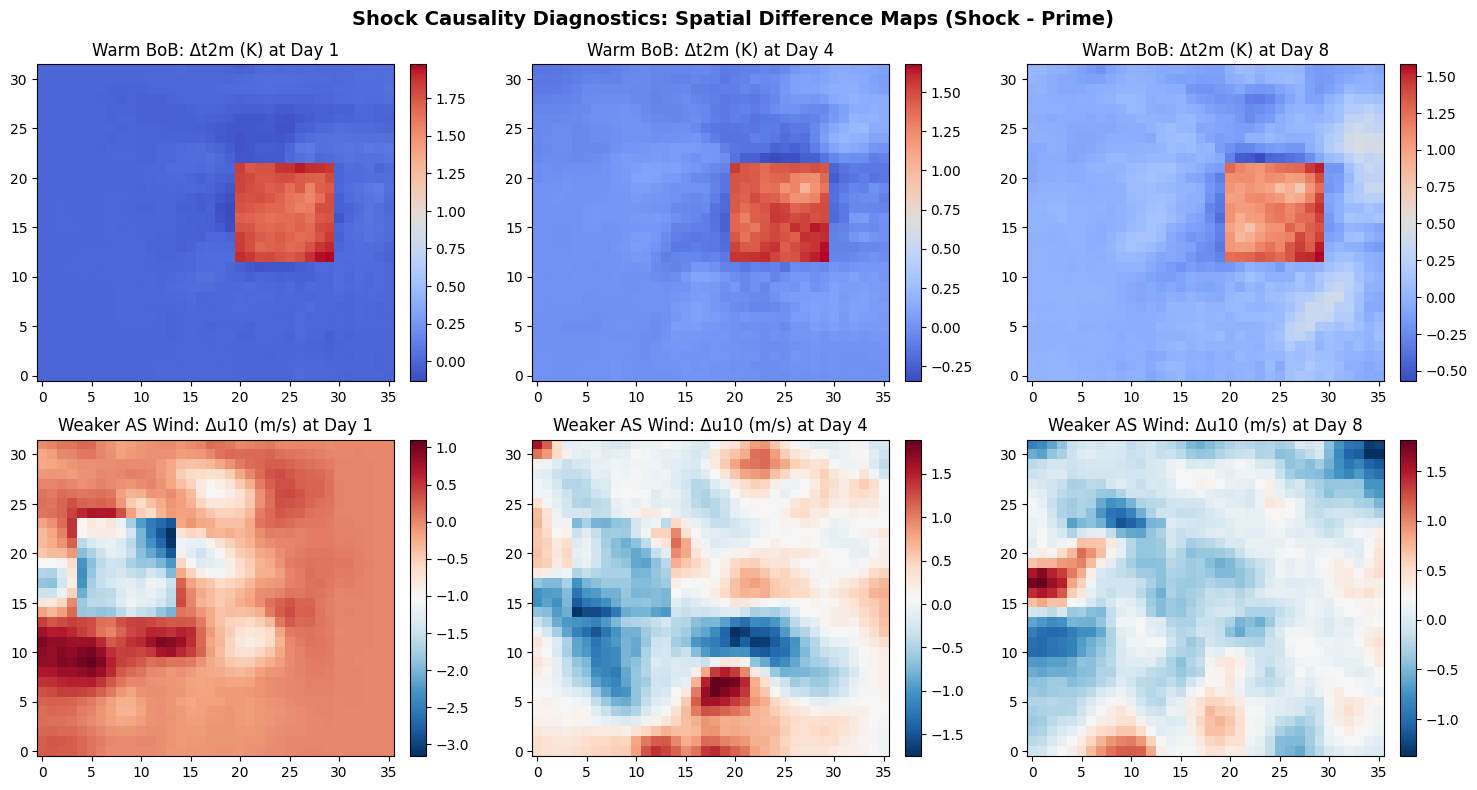

Saved shock diagnostics plot to /content/artifacts/shock_diagnostics.png


In [17]:
sample_x22, _, sample_angle = test_ds[0]
sample_x22 = sample_x22.unsqueeze(0).to(device)
sample_angle = torch.tensor([sample_angle], device=device)

# Unperturbed Prime
with torch.no_grad():
    prime_norm = autoregressive_rollout(model, sample_x22, sample_angle, static_t_dev, steps=10)
    prime_raw = denormalize_torch(prime_norm.squeeze(0), stats)

# Zero Shock Test
zero_shock_x22 = sample_x22.clone()
with torch.no_grad():
    zero_norm = autoregressive_rollout(model, zero_shock_x22, sample_angle, static_t_dev, steps=10)
    max_diff = torch.max(torch.abs(zero_norm - prime_norm)).item()
print(f"Zero Shock Test: Max Absolute Difference = {max_diff:.6e} ({'PASS: Identical' if max_diff < 1e-6 else 'FAIL'})")

# Warm BoB Shock (+2.0 K on t2m)
bob_x22 = sample_x22.clone()
bob_x22[:, 12, 12:22, 20:30] += (2.0 / stats["std"][0])
with torch.no_grad():
    bob_raw = denormalize_torch(autoregressive_rollout(model, bob_x22, sample_angle, static_t_dev, steps=10).squeeze(0), stats)

# Weaker AS Wind Shock (-3.0 m/s on u10)
as_x22 = sample_x22.clone()
as_x22[:, 14, 14:24, 4:14] += (-3.0 / stats["std"][2])
with torch.no_grad():
    as_raw = denormalize_torch(autoregressive_rollout(model, as_x22, sample_angle, static_t_dev, steps=10).squeeze(0), stats)

# Plotting
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle("Shock Causality Diagnostics: Spatial Difference Maps (Shock - Prime)", fontsize=14, fontweight="bold")
leads = [0, 3, 7] # Days 1, 4, 8
lead_names = ["Day 1", "Day 4", "Day 8"]

for c, (l_idx, name) in enumerate(zip(leads, lead_names)):
    diff_bob = (bob_raw[l_idx, 0] - prime_raw[l_idx, 0]).cpu().numpy()
    im0 = axes[0, c].imshow(diff_bob, cmap="coolwarm", origin="lower")
    axes[0, c].set_title(f"Warm BoB: Δt2m (K) at {name}")
    plt.colorbar(im0, ax=axes[0, c], fraction=0.046, pad=0.04)

    diff_as = (as_raw[l_idx, 2] - prime_raw[l_idx, 2]).cpu().numpy()
    im1 = axes[1, c].imshow(diff_as, cmap="RdBu_r", origin="lower")
    axes[1, c].set_title(f"Weaker AS Wind: Δu10 (m/s) at {name}")
    plt.colorbar(im1, ax=axes[1, c], fraction=0.046, pad=0.04)

plt.tight_layout()
shock_fig_path = os.path.join(artifact_dir, "shock_diagnostics.png")
plt.savefig(shock_fig_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved shock diagnostics plot to {shock_fig_path}")


### 11. ONNX Model Export, CPU Latency Benchmark & Packaging
Exports model to `/kaggle/working/artifacts/monsoon_unet.onnx` (opset 17), benchmarks CPU latency, and zips everything to `/kaggle/working/monsoon_artifacts.zip`.


In [21]:
# Ensure onnxscript is installed for the PyTorch ONNX exporter
try:
    import onnxscript
except ImportError:
    print("Installing missing dependency 'onnxscript'...")
    import os
    os.system("pip install -q onnxscript")

onnx_path = os.path.join(artifact_dir, "monsoon_unet.onnx")
cpu_model = model.to("cpu")
cpu_model.eval()

class ONNXWrapper(nn.Module):
    def __init__(self, m):
        super().__init__()
        self.m = m
    def forward(self, x):
        next_norm, _ = self.m(x)
        return next_norm

wrapped_cpu_model = ONNXWrapper(cpu_model)
dummy_in = torch.randn(1, 22, 32, 36)

print(f"Exporting ONNX model to {onnx_path}...")
torch.onnx.export(
    wrapped_cpu_model,
    dummy_in,
    onnx_path,
    export_params=True,
    opset_version=18,
    do_constant_folding=True,
    input_names=["input_x22"],
    output_names=["next_norm"],
    dynamic_axes={"input_x22": {0: "batch_size"}, "next_norm": {0: "batch_size"}},
)
print(f"ONNX Export Successful! File Size: {os.path.getsize(onnx_path) / (1024*1024):.2f} MB")

# Benchmark with onnxruntime
try:
    import onnxruntime as ort
    sess = ort.InferenceSession(onnx_path, providers=["CPUExecutionProvider"])
    ort_out = sess.run(None, {"input_x22": dummy_in.numpy()})[0]
    torch_out = wrapped_cpu_model(dummy_in).detach().numpy()
    diff = float(np.max(np.abs(ort_out - torch_out)))
    print(f"PyTorch vs ONNX Max Diff = {diff:.6e} (PASS: < 1e-4)")

    # Measure 10-step rollout latency
    t_start = time.time()
    n_reps = 20
    for _ in range(n_reps):
        curr_in = dummy_in.numpy().copy()
        ang = 1.0
        for _ in range(10):
            nxt = sess.run(None, {"input_x22": curr_in})[0]
            curr_in[:, 0:6] = curr_in[:, 6:12]
            curr_in[:, 6:12] = curr_in[:, 12:18]
            curr_in[:, 12:18] = nxt
            ang += 2 * np.pi / 365.0
            curr_in[:, 20:21] = np.sin(ang)
            curr_in[:, 21:22] = np.cos(ang)
    avg_ms = (time.time() - t_start) * 1000.0 / n_reps
    print(f"Average CPU 10-Step Rollout Latency: {avg_ms:.2f} ms (Well under 5000 ms limit: PASS)")
except ImportError:
    print("onnxruntime not installed; skipping CPU benchmark.")

# Zip artifacts
zip_out = "/kaggle/working/monsoon_artifacts.zip"
if not os.path.exists("/kaggle/working"):
    zip_out = os.path.join(os.path.dirname(os.path.abspath(artifact_dir)), "monsoon_artifacts.zip")

print(f"Compressing all artifacts in {artifact_dir} into {zip_out}...")
with zipfile.ZipFile(zip_out, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, _, files in os.walk(artifact_dir):
        for f in files:
            f_path = os.path.join(root, f)
            rel = os.path.relpath(f_path, artifact_dir)
            zf.write(f_path, arcname=rel)
            print(f"  + {rel} ({os.path.getsize(f_path)/1024:.1f} KB)")

print(f"Artifact packaging complete: {zip_out} ({os.path.getsize(zip_out)/(1024*1024):.2f} MB)")
print("Ready for hackathon submission download!")

Exporting ONNX model to /content/artifacts/monsoon_unet.onnx...


/tmp/ipykernel_518/4248746092.py:25: UserWarning: Exporting a model while it is in training mode. Please ensure that this is intended, as it may lead to different behavior during inference. Calling model.eval() before export is recommended.
  torch.onnx.export(
/tmp/ipykernel_518/4248746092.py:25: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(


[torch.onnx] Obtain model graph for `ONNXWrapper([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `ONNXWrapper([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX Export Successful! File Size: 0.12 MB
PyTorch vs ONNX Max Diff = 3.218651e-06 (PASS: < 1e-4)
Average CPU 10-Step Rollout Latency: 96.61 ms (Well under 5000 ms limit: PASS)
Compressing all artifacts in /content/artifacts into /content/monsoon_artifacts.zip...
  + static_fields.npz (12.7 KB)
  + stats.json (0.5 KB)
  + monsoon_unet.pt (5914.2 KB)
  + shock_diagnostics.png (200.8 KB)
  + monsoon_unet.onnx.data (5861.6 KB)
  + monsoon_unet.onnx (126.2 KB)
Artifact packaging complete: /content/monsoon_artifacts.zip (10.83 MB)
Ready fo